# RQ2 | Which attributes show stronger within-group friendship?
Political orientation, religion and gender are measured on the same valid primary graphs using the categorical Coleman index. Zero means same-group ties match the group's share of the roster; positive means more same-group ties. The graph score weights group-specific scores by roster shares. It is **not the percentage of ties**. Numeric age uses a different statistic and is not ranked here.

This is an exploratory, descriptive addition to the [original analyses](01_primary_statistical_analysis.ipynb), not another test in the locked family of 24. No supplement, provider call or ledger is used.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'analysis_figures/publication_v3.py').is_file())
def pinned_csv(rel, digest):
    data = (root / rel).read_bytes()
    assert hashlib.sha256(data).hexdigest() == digest, f'Primary input changed: {rel}'
    return pd.read_csv(BytesIO(data)).set_index('run_id', verify_integrity=True)

metrics = pinned_csv('outputs/final_study/060dcd3a86d5/main/network_metrics.csv',
                     'e6d6227c31cecd6dbb01ad34db8c32c9e0afe89c365d90c2872adc3e83f1b03a')
catalog = pinned_csv('outputs/analysis_ready/060dcd3a86d5/primary_valid_graphs.csv',
                     'f62db1d6ae788193af39005fd92a969d5418bd2d7fa1acef437577aa5edf5591')
assert len(metrics) == 896 and len(catalog) == 890 and catalog.cohort.eq('primary').all()
assert set(metrics.index[metrics.valid_graph]) == set(catalog.index)
attrs = ['Political orientation', 'Religion', 'Gender']
keys = ['method', 'model', 'culture', 'language']
rows = metrics.loc[catalog.index].rename(columns=dict(zip(
    ['coleman_political orientation', 'coleman_religion', 'coleman_gender'], attrs)))
defined = np.isfinite(rows[attrs]).all(axis=1)
assert (~defined).equals(catalog.empty_graph) and defined.sum() == 878
rows = rows.loc[defined, keys + attrs]
print('896 planned primary attempts | 6 failed | 890 valid | 12 empty | 878 scored | 0 supplements')

896 planned primary attempts | 6 failed | 890 valid | 12 empty | 878 scored | 0 supplements


## Compare like with like
First average each score across the available seeds **within** one model, generation method and instruction condition. Panel A gives the 28 resulting combinations per method equal weight. Panel B counts which attribute has the largest **unrounded** mean in each combination. This is not the fraction of people or graphs who chose a political friend.

In [2]:
methods = ['global', 'local', 'sequential', 'iterative']
groups = rows.groupby(keys, sort=True)
cells = groups[attrs].mean()
n = groups.size()
assert len(cells) == 112 and cells.groupby(level='method').size().eq(28).all()
assert n.between(1, 8).all() and n.sum() == 878
assert cells.eq(cells.max(axis=1), axis=0).sum(axis=1).eq(1).all(), 'Tied leaders: do not break ties silently'
means = cells.groupby(level='method').mean().loc[methods]
leaders = cells.idxmax(axis=1)
wins = pd.crosstab(leaders.index.get_level_values('method'), leaders).reindex(index=methods, columns=attrs, fill_value=0)
assert wins.sum(axis=1).eq(28).all() and wins.sum().tolist() == [90, 22, 0]
display(pd.concat({'Mean Coleman score': means.round(3), 'Combinations ranked first': wins}, axis=1))

Mean Coleman score                 Combinations ranked first  \
           Political orientation Religion Gender     Political orientation   
global                     0.509    0.639  0.356                         6   
local                      0.579    0.249  0.174                        28   
sequential                 0.524    0.246  0.151                        28   
iterative                  0.714    0.126  0.129                        28   

                            
           Religion Gender  
global           22      0  
local             0      0  
sequential        0      0  
iterative         0      0

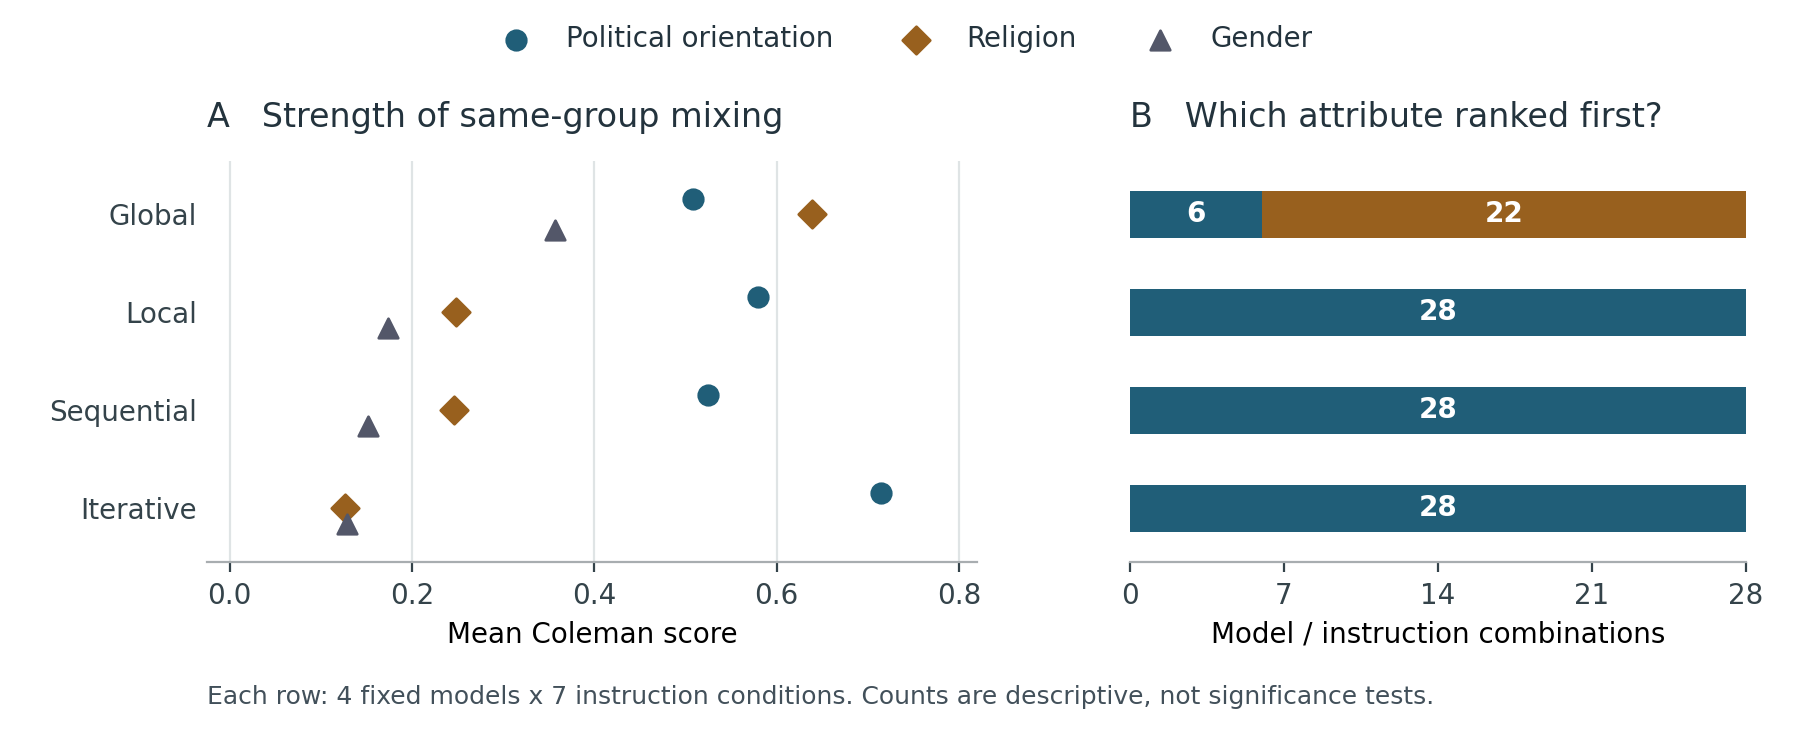

In [3]:
colors = ['#205E78', '#98601E', '#535769']
markers = ['o', 'D', '^']
y = np.arange(len(methods))
with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': '#A8ADB0',
                     'text.color': '#23333D', 'xtick.color': '#34434A', 'ytick.color': '#34434A'}):
    fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.65), gridspec_kw={'width_ratios': [1.25, 1]})
    fig.subplots_adjust(left=.115, right=.97, bottom=.23, top=.78, wspace=.22)
    for ax in (a, b):
        ax.spines[['top', 'right', 'left']].set_visible(False)
        ax.tick_params(axis='y', length=0)
        ax.set_ylim(3.55, -.55)
        ax.set_axisbelow(True)
    for i, label in enumerate(attrs):
        a.scatter(means[label], y + (i-1)*.16, s=49, color=colors[i], marker=markers[i], label=label, zorder=3)
    a.set(yticks=y, yticklabels=[m.title() for m in methods], xlim=(-.025,.82),
          xticks=[0,.2,.4,.6,.8], xlabel='Mean Coleman score')
    a.grid(axis='x', color='#DFE4E5', linewidth=.8)
    a.set_title('A   Strength of same-group mixing', loc='left', fontsize=12, pad=12)
    left = np.zeros(len(methods), dtype=int)
    for label, color in zip(attrs, colors):
        counts = wins[label].to_numpy()
        b.barh(y, counts, left=left, height=.48, color=color)
        for j, number in enumerate(counts):
            if number:
                b.text(left[j]+number/2, j, str(number), ha='center', va='center', color='white', fontweight='bold')
        left += counts
    b.set(yticks=[], xlim=(0,28), xticks=[0,7,14,21,28], xlabel='Model / instruction combinations')
    b.set_title('B   Which attribute ranked first?', loc='left', fontsize=12, pad=12)
    fig.legend(*a.get_legend_handles_labels(), loc='upper center', ncol=3, frameon=False, columnspacing=2)
    fig.text(.115,.035,'Each row: 4 fixed models x 7 instruction conditions. Counts are descriptive, not significance tests.',
             fontsize=9, color='#42505A')
    buf = BytesIO()
    fig.savefig(buf, format='png', dpi=200, facecolor='white')
    plt.close(fig)
png = buf.getvalue()
display(Image(data=png))

**Read the global row first.** Religion leads in 22/28 combinations and political orientation in 6/28. For local, sequential and iterative generation, political orientation leads in 28/28 each. Gender never ranks first, but its mean is positive in every method. These are descriptive comparisons on one fictional roster, not independent population votes, causal estimates or evidence about the motives behind actual friendships.

For audit, `cells` contains all 112 unrounded score triples and `n` their contributing graph counts. The public [figure PNG](../outputs/publication_figures/20261110_rq2/14_demographic_mixing.png) is the exact image embedded above.